# 01 — Exploration des données Telco Customer Churn

**Objectif** : comprendre les données avant de modéliser.

1. **Qualité des données** (sur le fichier brut complet) : taille, types, valeurs manquantes,
   doublons. Ces contrôles ne regardent pas la cible.
2. **Liens avec le départ** (sur le **train uniquement**) : répartition de la cible, contrat,
   ancienneté, montants, services.

> Pourquoi le train seulement pour la partie 2 ? Regarder la validation ou le test
> influencerait nos choix (variables, seuils, regroupements) : ce serait une fuite
> d'information « humaine ». Ces parties doivent rester une estimation honnête.

Tous les chiffres de ce notebook sont produits par son exécution.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from churnguard.config import load_config, resolve_path
from churnguard.data import get_splits, load_raw

cfg = load_config()
NUM = cfg["columns"]["numeric"]
CAT = cfg["columns"]["categorical"]

# Palette : bleu = resté, orange = parti ; texte et axes en gris discret.
STAYED, CHURNED, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
sns.set_theme(
    style="whitegrid",
    rc={
        "axes.edgecolor": "#d9d8d4",
        "grid.color": "#ecebe8",
        "axes.labelcolor": MUTED,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "text.color": INK,
        "axes.titleweight": "bold",
        "figure.dpi": 110,
    },
)
pd.set_option("display.max_columns", 30)

## 1. Qualité des données (fichier brut complet)

In [2]:
raw = load_raw(resolve_path(cfg["paths"]["raw_data"]))
print("Taille :", raw.shape)


# Résumé par colonne plutôt que raw.head() : on n'affiche pas de lignes réelles
# dans un notebook versionné tant que la licence des données n'est pas confirmée.
def modalities(s: pd.Series) -> str:
    return ", ".join(map(str, sorted(s.unique()))) if s.nunique() <= 4 else ""


pd.DataFrame(
    {
        "dtype": raw.dtypes.astype(str),
        "valeurs distinctes": raw.nunique(),
        "modalités (si ≤ 4)": raw.apply(modalities),
    }
)

Taille : (7043, 21)


,dtype,valeurs distinctes,modalités (si ≤ 4)
customerID,str,7043,
gender,str,2,"Female, Male"
SeniorCitizen,int64,2,"0, 1"
Partner,str,2,"No, Yes"
Dependents,str,2,"No, Yes"
tenure,int64,73,
PhoneService,str,2,"No, Yes"
MultipleLines,str,3,"No, No phone service, Yes"
InternetService,str,3,"DSL, Fiber optic, No"
OnlineSecurity,str,3,"No, No internet service, Yes"


`TotalCharges` est lu comme du **texte** alors que c'est un montant : il contient donc des valeurs
non numériques. `SeniorCitizen` est un entier 0/1 alors que les autres variables binaires sont en
Yes/No.

In [3]:
na_counts = raw.isna().sum()
blank_counts = raw.select_dtypes(exclude="number").apply(lambda s: (s.str.strip() == "").sum())
pd.DataFrame({"NaN": na_counts, "chaînes vides": blank_counts}).fillna(0).astype(int).query(
    "NaN > 0 or `chaînes vides` > 0"
)

,NaN,chaînes vides
TotalCharges,0,11


In [4]:
total_num = pd.to_numeric(raw["TotalCharges"], errors="coerce")
non_numeric = raw.loc[total_num.isna(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]
print(f"Lignes où TotalCharges n'est pas numérique : {len(non_numeric)}")
print("Valeurs de tenure sur ces lignes :", sorted(non_numeric["tenure"].unique().tolist()))
print("Valeurs brutes de TotalCharges :", non_numeric["TotalCharges"].unique().tolist())
print("Autres clients avec tenure = 0 :", int((raw["tenure"] == 0).sum()) - len(non_numeric))

Lignes où TotalCharges n'est pas numérique : 11
Valeurs de tenure sur ces lignes : [0]
Valeurs brutes de TotalCharges : [' ']


Autres clients avec tenure = 0 : 0


In [5]:
print("customerID en double :", raw["customerID"].duplicated().sum())
print(
    "Lignes entièrement dupliquées (hors customerID) :",
    raw.drop(columns="customerID").duplicated().sum(),
)
print("Valeurs de Churn :", raw["Churn"].value_counts().to_dict())

customerID en double : 0
Lignes entièrement dupliquées (hors customerID) : 22
Valeurs de Churn : {'No': 5174, 'Yes': 1869}


**Décisions de nettoyage** (implémentées dans `churnguard.data.clean`, pas dans ce notebook) :

- `TotalCharges` → nombre ; les valeurs vides concernent uniquement des clients avec `tenure = 0`,
  qui n'ont encore rien payé → **0**. Règle ligne par ligne, sans statistique apprise : pas de fuite.
- `SeniorCitizen` 0/1 → No/Yes, `Churn` Yes/No → 1/0, `customerID` exclu des variables explicatives.
- Les lignes identiques hors `customerID` sont des clients distincts au profil identique (variables
  peu nombreuses et surtout catégorielles) : on les garde.

## 2. Liens avec le départ (train uniquement)

In [6]:
splits = get_splits(cfg)
train = splits["train"]
for name, part in splits.items():
    print(f"{name:<5} : {len(part):>5} lignes, taux de départ = {part['Churn'].mean():.2%}")

train :  4225 lignes, taux de départ = 26.53%
val   :  1409 lignes, taux de départ = 26.54%
test  :  1409 lignes, taux de départ = 26.54%


### 2.1 Répartition de la cible

Churn
resté (0)    3104
parti (1)    1121
Taux de départ : 26.53%
Exactitude d'un modèle qui prédit toujours « resté » : 73.47%


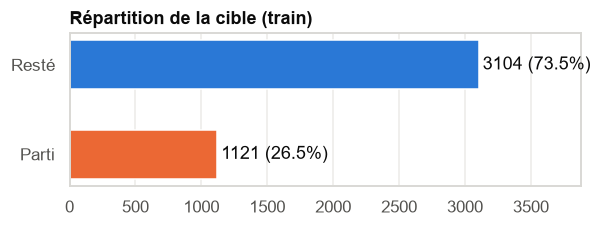

In [7]:
counts = train["Churn"].value_counts().sort_index()
rate = train["Churn"].mean()
print(counts.rename({0: "resté (0)", 1: "parti (1)"}).to_string())
print(f"Taux de départ : {rate:.2%}")
print(f"Exactitude d'un modèle qui prédit toujours « resté » : {1 - rate:.2%}")

fig, ax = plt.subplots(figsize=(6, 1.8))
ax.barh(["Parti", "Resté"], [counts[1], counts[0]], color=[CHURNED, STAYED], height=0.55)
for y, v in enumerate([counts[1], counts[0]]):
    ax.text(v + 30, y, f"{v} ({v / counts.sum():.1%})", va="center", color=INK)
ax.set_xlim(0, counts.max() * 1.25)
ax.set_title("Répartition de la cible (train)", loc="left")
ax.grid(axis="y", visible=False)
plt.show()

> **Pourquoi l'exactitude (accuracy) est trompeuse** : avec des classes déséquilibrées, un modèle qui
> prédit toujours la classe majoritaire obtient une exactitude élevée (ci-dessus) tout en ne
> détectant **aucun** départ — exactement les clients qui nous intéressent. On suivra donc plutôt le
> rappel, la précision, le F1, la ROC-AUC et la PR-AUC.

### 2.2 Taux de départ par variable catégorielle

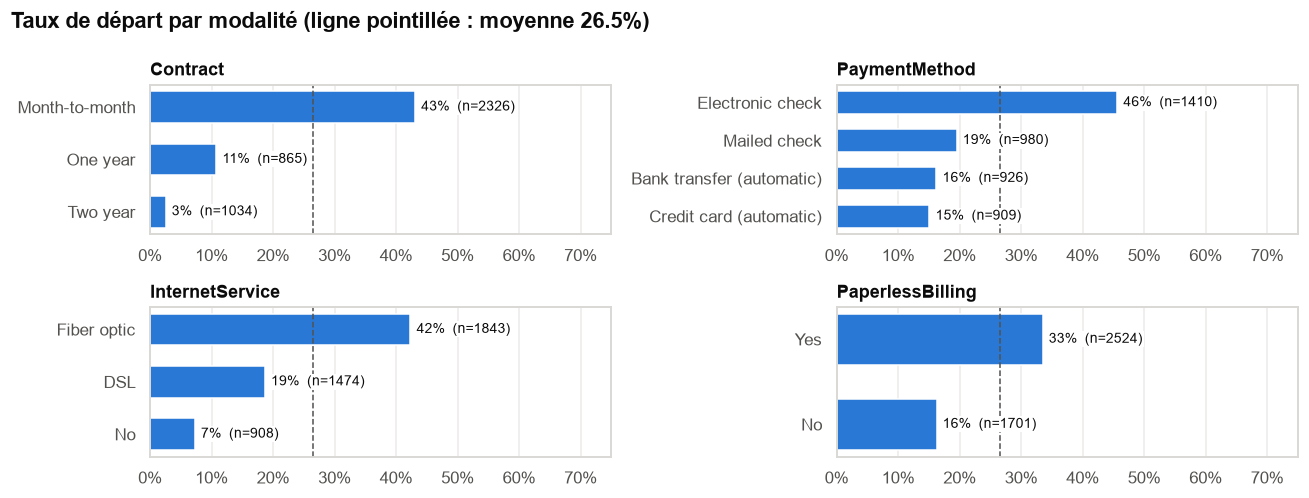

In [8]:
def churn_rate_table(df: pd.DataFrame, col: str) -> pd.DataFrame:
    g = df.groupby(col, observed=True)["Churn"].agg(clients="size", taux_depart="mean")
    return g.sort_values("taux_depart", ascending=False)


def plot_churn_rate(df: pd.DataFrame, cols: list[str], ncols: int = 2) -> None:
    overall = df["Churn"].mean()
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 2.3 * nrows), squeeze=False)
    for ax, col in zip(axes.flat, cols, strict=False):
        t = churn_rate_table(df, col).iloc[::-1]
        ax.barh(t.index.astype(str), t["taux_depart"], color=STAYED, height=0.6)
        ax.axvline(overall, color=MUTED, lw=1, ls="--")
        for y, (r, n) in enumerate(zip(t["taux_depart"], t["clients"], strict=True)):
            ax.text(
                r + 0.01,
                y,
                f"{r:.0%}  (n={n})",
                va="center",
                fontsize=9,
                color=INK,
                bbox={"facecolor": "white", "edgecolor": "none", "pad": 1},
            )
        ax.set_xlim(0, 0.75)
        ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
        ax.set_title(col, loc="left")
        ax.grid(axis="y", visible=False)
    for ax in axes.flat[len(cols) :]:
        ax.set_visible(False)
    fig.suptitle(
        f"Taux de départ par modalité (ligne pointillée : moyenne {overall:.1%})",
        x=0.01,
        ha="left",
        fontweight="bold",
    )
    fig.tight_layout()
    plt.show()


plot_churn_rate(train, ["Contract", "PaymentMethod", "InternetService", "PaperlessBilling"])

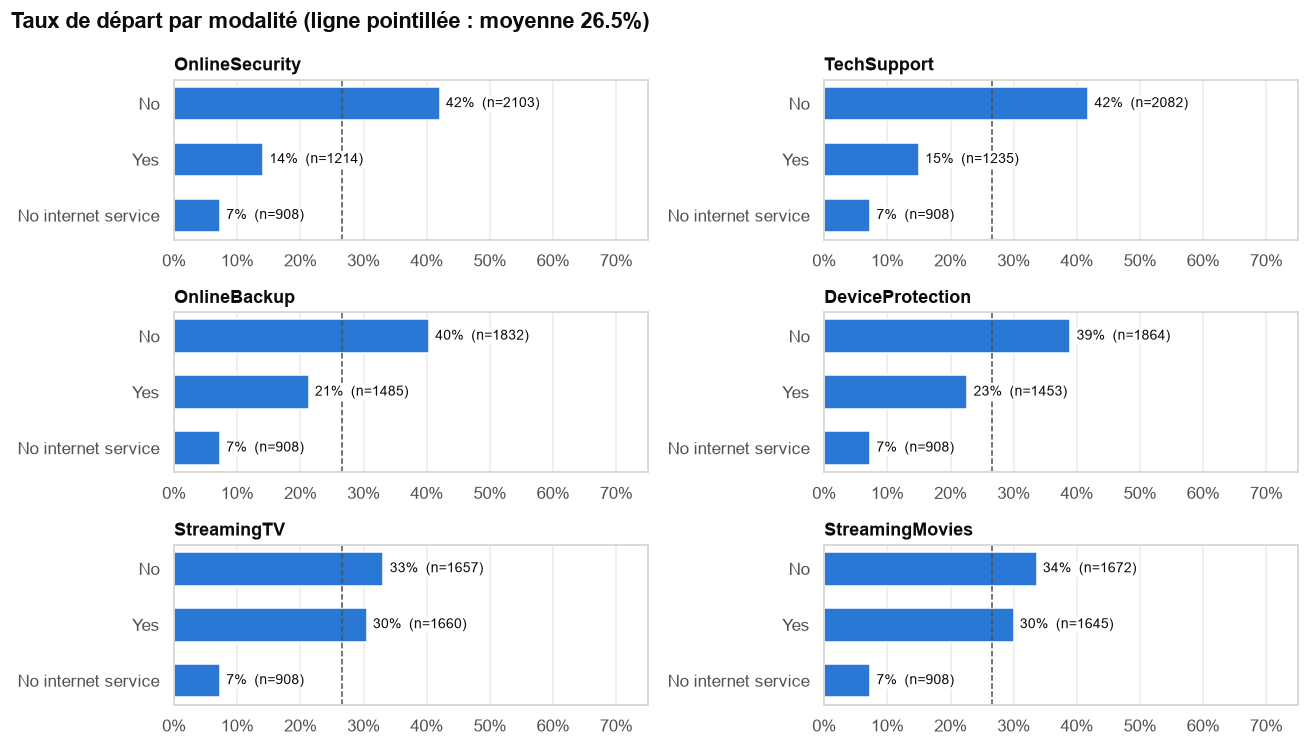

In [9]:
plot_churn_rate(
    train,
    [
        "OnlineSecurity",
        "TechSupport",
        "OnlineBackup",
        "DeviceProtection",
        "StreamingTV",
        "StreamingMovies",
    ],
)

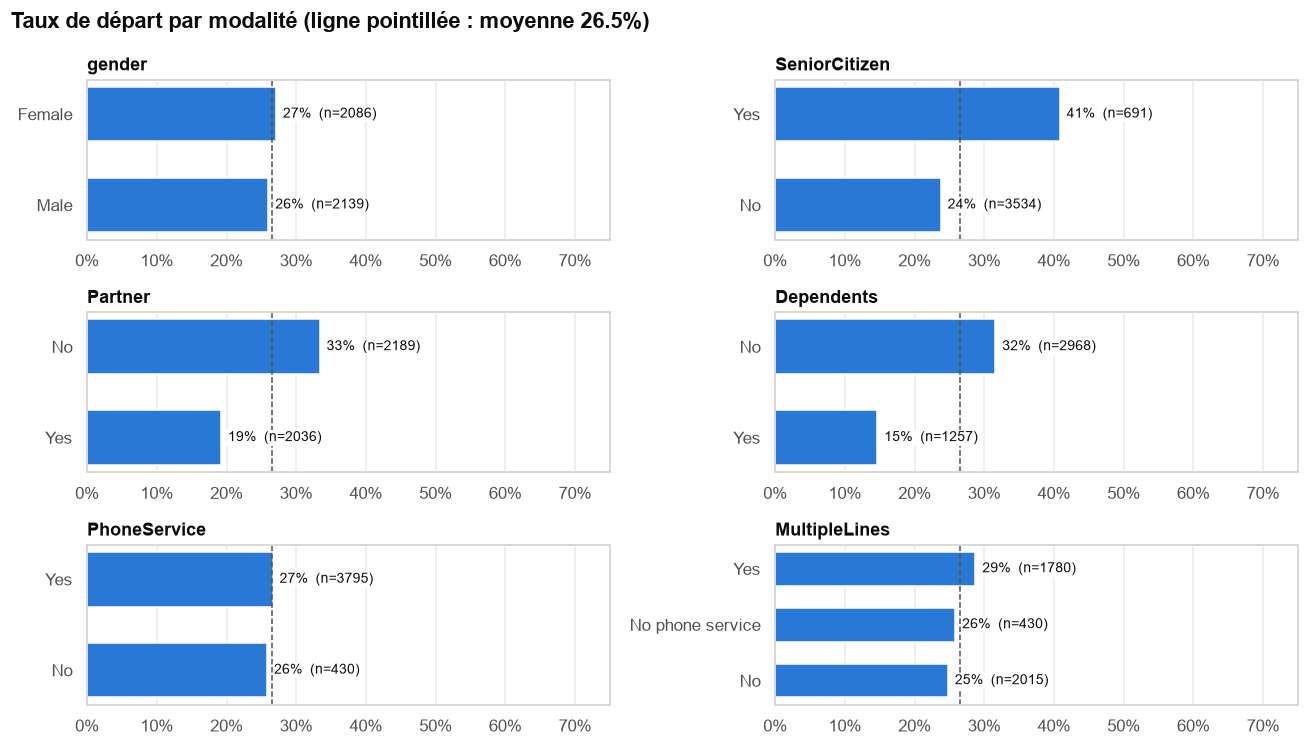

In [10]:
plot_churn_rate(
    train, ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines"]
)

Pour comparer toutes les variables catégorielles d'un coup, on mesure l'**écart de taux de départ**
entre la modalité la plus risquée et la moins risquée (c'est descriptif, pas causal : plusieurs
variables sont liées entre elles).

In [11]:
spread = pd.DataFrame(
    {
        col: {
            "modalité la plus risquée": (t := churn_rate_table(train, col)).index[0],
            "taux max": t["taux_depart"].iloc[0],
            "modalité la moins risquée": t.index[-1],
            "taux min": t["taux_depart"].iloc[-1],
        }
        for col in CAT
    }
).T
spread["écart"] = spread["taux max"] - spread["taux min"]
spread.sort_values("écart", ascending=False).style.format(
    {"taux max": "{:.1%}", "taux min": "{:.1%}", "écart": "{:.1%}"}
)

,modalité la plus risquée,taux max,modalité la moins risquée,taux min,écart
Contract,Month-to-month,43.1%,Two year,2.5%,40.6%
InternetService,Fiber optic,42.3%,No,7.3%,35.1%
OnlineSecurity,No,42.0%,No internet service,7.3%,34.8%
TechSupport,No,41.8%,No internet service,7.3%,34.5%
OnlineBackup,No,40.3%,No internet service,7.3%,33.1%
DeviceProtection,No,38.9%,No internet service,7.3%,31.7%
PaymentMethod,Electronic check,45.6%,Credit card (automatic),15.1%,30.5%
StreamingMovies,No,33.6%,No internet service,7.3%,26.3%
StreamingTV,No,33.1%,No internet service,7.3%,25.9%
PaperlessBilling,Yes,33.5%,No,16.2%,17.3%


### 2.3 Variables numériques : ancienneté et montants

In [12]:
train.groupby("Churn")[NUM].describe().T.round(1).rename(columns={0: "resté", 1: "parti"})

Churn                  resté   parti
tenure         count  3104.0  1121.0
               mean     37.5    17.8
               std      24.3    19.4
               min       0.0     1.0
               25%      15.0     2.0
               50%      37.0    10.0
               75%      61.0    29.0
               max      72.0    72.0
MonthlyCharges count  3104.0  1121.0
               mean     61.2    74.5
               std      31.0    24.6
               min      18.4    18.8
               25%      25.2    56.0
               50%      64.4    79.8
               75%      87.1    94.4
               max     118.8   118.4
TotalCharges   count  3104.0  1121.0
               mean   2560.8  1517.7
               std    2349.6  1875.1
               min       0.0    18.8
               25%     563.4   131.6
               50%    1672.1   679.3
               75%    4298.3  2277.6
               max    8672.4  8684.8

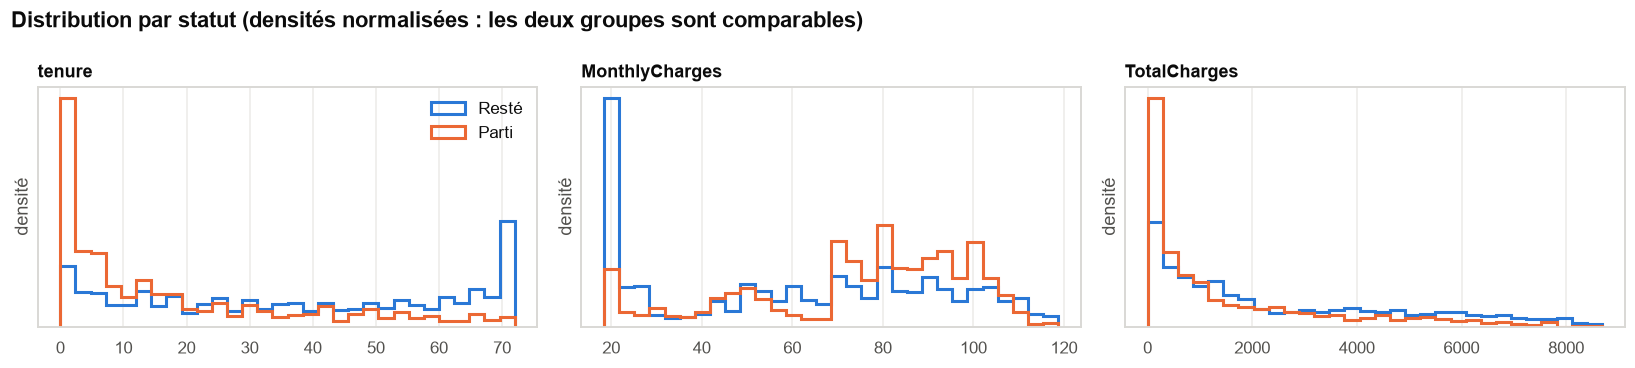

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
labels = {0: "Resté", 1: "Parti"}
for ax, col in zip(axes, NUM, strict=True):
    bins = np.histogram_bin_edges(train[col], bins=30)
    for value, color in [(0, STAYED), (1, CHURNED)]:
        ax.hist(
            train.loc[train["Churn"] == value, col],
            bins=bins,
            density=True,
            histtype="step",
            lw=2,
            color=color,
            label=labels[value],
        )
    ax.set_title(col, loc="left")
    ax.set_yticks([])
    ax.set_ylabel("densité")
axes[0].legend(frameon=False)
fig.suptitle(
    "Distribution par statut (densités normalisées : les deux groupes sont comparables)",
    x=0.01,
    ha="left",
    fontweight="bold",
)
fig.tight_layout()
plt.show()

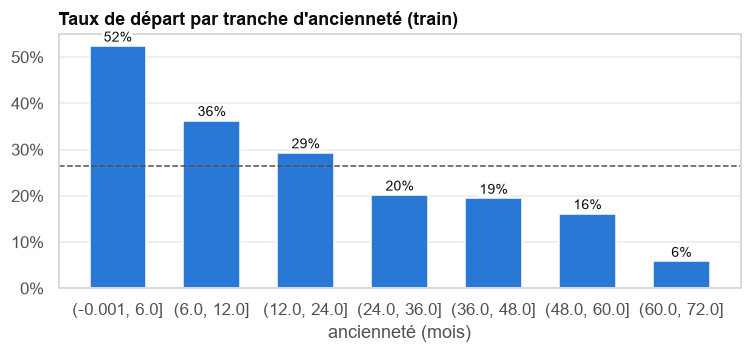

,clients,taux_depart
tenure,,
"(-0.001, 6.0]",904,52.3%
"(6.0, 12.0]",414,36.2%
"(12.0, 24.0]",629,29.3%
"(24.0, 36.0]",492,20.1%
"(36.0, 48.0]",448,19.4%
"(48.0, 60.0]",491,16.1%
"(60.0, 72.0]",847,5.8%


In [14]:
bins = [0, 6, 12, 24, 36, 48, 60, 72]
tenure_band = pd.cut(train["tenure"], bins=bins, include_lowest=True)
t = train.groupby(tenure_band, observed=True)["Churn"].agg(clients="size", taux_depart="mean")

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(t.index.astype(str), t["taux_depart"], color=STAYED, width=0.6)
ax.axhline(train["Churn"].mean(), color=MUTED, lw=1, ls="--")
for x, r in enumerate(t["taux_depart"]):
    ax.text(
        x,
        r + 0.01,
        f"{r:.0%}",
        ha="center",
        fontsize=9,
        color=INK,
        bbox={"facecolor": "white", "edgecolor": "none", "pad": 1},
    )
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xlabel("ancienneté (mois)")
ax.set_title("Taux de départ par tranche d'ancienneté (train)", loc="left")
ax.grid(axis="x", visible=False)
plt.show()
t.style.format({"taux_depart": "{:.1%}"})

In [15]:
pd.crosstab(
    train["Contract"],
    pd.cut(train["tenure"], bins=bins, include_lowest=True),
    values=train["Churn"],
    aggfunc="mean",
).style.format("{:.0%}").background_gradient(cmap="Blues", axis=None)

tenure,"(-0.001, 6.0]","(6.0, 12.0]","(12.0, 24.0]","(24.0, 36.0]","(36.0, 48.0]","(48.0, 60.0]","(60.0, 72.0]"
Contract,,,,,,,
Month-to-month,55%,42%,39%,30%,35%,34%,24%
One year,6%,11%,7%,8%,14%,14%,10%
Two year,0%,0%,0%,2%,1%,5%,3%


Ce tableau croise contrat et ancienneté : il permet de voir si l'effet du contrat tient à
ancienneté égale, ou s'il ne fait que refléter le fait que les contrats longs concernent surtout
des clients anciens.

### 2.4 Corrélations entre variables numériques

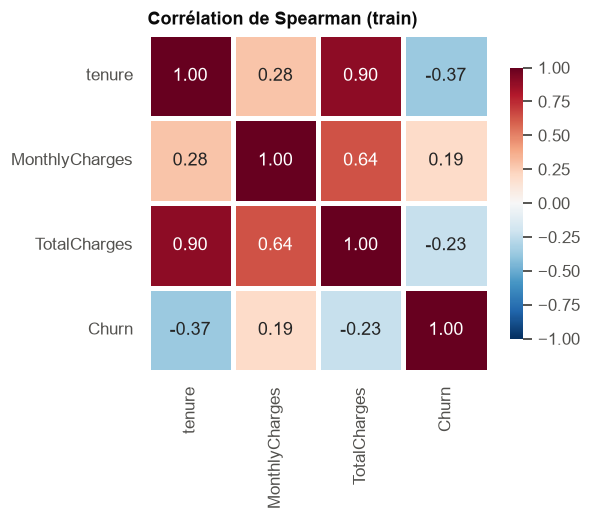

In [16]:
corr = train[NUM + ["Churn"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=2,
    linecolor="white",
    cbar_kws={"shrink": 0.8},
    ax=ax,
)
ax.set_title("Corrélation de Spearman (train)", loc="left")
plt.show()

In [17]:
ratio = train.loc[train["tenure"] > 0, "TotalCharges"] / (
    train.loc[train["tenure"] > 0, "tenure"] * train.loc[train["tenure"] > 0, "MonthlyCharges"]
)
print("TotalCharges / (tenure × MonthlyCharges) :")
print(ratio.describe().round(3).to_string())

TotalCharges / (tenure × MonthlyCharges) :
count    4218.000
mean        1.001
std         0.051
min         0.690
25%         0.980
50%         1.000
75%         1.019
max         1.531


> **Corrélation de Spearman** : elle mesure si deux variables évoluent dans le même sens (sur les
> rangs), même de façon non linéaire, et reste robuste aux valeurs extrêmes. Une corrélation forte
> entre deux variables explicatives (colinéarité) n'empêche pas de prédire, mais rend les
> coefficients d'une régression logistique moins interprétables individuellement.

## 3. Conclusions

Constats sur le **train** (4 225 clients), descriptifs et non causaux :

- **Qualité** : 7 043 lignes, 21 colonnes, aucun `customerID` en double. Seule anomalie :
  11 `TotalCharges` vides, tous pour des clients à `tenure = 0` → mis à 0 au nettoyage.
- **Déséquilibre** : 26,5 % de départs. Prédire toujours « resté » donne 73,5 % d'exactitude
  sans détecter un seul départ → l'exactitude n'est pas la bonne métrique ici.
- **Contrat** : c'est la variable la plus discriminante. 43 % de départ en mensuel, 11 % sur un an,
  3 % sur deux ans. L'effet persiste à ancienneté égale (tableau croisé) : en mensuel, le taux
  reste entre 24 % et 55 % selon la tranche d'ancienneté, contre 14 % au plus pour les
  contrats longs (effectifs faibles pour ces derniers dans les premières tranches).
- **Ancienneté** : 52 % de départ pendant les 6 premiers mois, 6 % au-delà de 60 mois.
  Les départs se concentrent chez les clients récents (médiane de 10 mois contre 37).
- **Internet** : la fibre (42 %) part bien plus que le DSL (19 %) et que les clients sans internet
  (7 %). Les clients partis ont des factures mensuelles plus élevées (médiane 79,8 contre 64,4).
- **Services de protection** : sans `OnlineSecurity` ou `TechSupport`, environ 42 % de départ.
- **Paiement** : le chèque électronique (46 %) ressort nettement face aux paiements automatiques
  (15-16 %). La facturation dématérialisée aussi (33 % contre 16 %).
- **Peu informatives seules** : `gender`, `PhoneService`, `MultipleLines` (écart < 4 points).
- **Colinéarité** : `TotalCharges` ≈ `tenure × MonthlyCharges` (ratio médian 1,00) et une
  corrélation de Spearman de 0,90 avec `tenure`. À garder en tête pour interpréter les
  coefficients de la régression logistique ; ce n'est pas bloquant pour la prédiction.
- Plusieurs modalités « No internet service » sont redondantes avec `InternetService = No`.

**Pour la modélisation** : variables catégorielles en one-hot, numériques normalisées, et métriques
adaptées au déséquilibre (rappel, précision, F1, ROC-AUC, PR-AUC) plutôt que l'exactitude.